# EfficientAD — Student-Teacher Local Anomaly Detection

## Overview

We implement the **student-teacher knowledge distillation** branch of EfficientAD for unsupervised anomaly detection on the **MVTec AD Bottle** category.

**Idea:** A lightweight *student* network (Patch Description Network, PDN) is trained to mimic a frozen *pretrained teacher* on **normal** images only. At test time, the student fails to reproduce the teacher's output on anomalous regions, producing a detectable discrepancy.

---

## Key Formulas

**Knowledge Distillation Loss (training):**

$$\mathcal{L}_{\text{KD}} = \frac{1}{HW} \sum_{h,w} \left\| T(x)_{h,w} - S(x)_{h,w} \right\|_2^2$$

where $T$ is the frozen teacher, $S$ is the student PDN, and the sum runs over spatial positions of the feature map.

**Hard Example Mining:** Only the top-$p$% loss pixels are kept per image (default $p=99.9$ during early training → $p=99$ later) to focus on the hardest patches.

**Anomaly Score (inference):**

$$\mathcal{A}(x)_{h,w} = \left\| T(x)_{h,w} - S(x)_{h,w} \right\|_2^2$$

The anomaly map is upsampled to the input resolution and Gaussian-smoothed.

---

## Architecture

| Component | Architecture | Notes |
|-----------|-------------|-------|
| **Teacher** | WideResNet-101 (or ResNet-18) | Frozen, pretrained on ImageNet |
| **Student (PDN)** | 4 Conv + 2 FC layers | Lightweight, ~0.3M params |

---

## Pipeline

1. **Dataset** — Load MVTec AD Bottle (train = good only; test = good + defect).
2. **Teacher features** — Extract intermediate features from the frozen teacher.
3. **Train student** — Minimise $\mathcal{L}_{\text{KD}}$ on normal training images.
4. **Inference** — Compute anomaly map $\mathcal{A}(x)$ on test images.
5. **Visualize** — Overlay anomaly heatmaps on test images.

In [2]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from scipy.ndimage import gaussian_filter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cpu


## 1. Model Definitions

### Teacher Network

We use a **pretrained ResNet-18** as the teacher. We extract features from `layer1` (64-ch, stride 4) and `layer2` (128-ch, stride 8), upsample `layer2` to match `layer1`'s spatial size, then project the concatenated 192-ch map to `OUT_CHANNELS = 384` via a 1×1 convolution. The teacher is **frozen** — no gradients flow through it.

The output resolution is **H/4 × W/4** = **64 × 64** for a 256 × 256 input.

### Student Network — Patch Description Network (PDN)

The PDN follows the EfficientAD "small" variant:

| Layer | Type | Kernel | Stride | Padding | Out Channels |
|-------|------|--------|--------|---------|-------------|
| 1 | Conv2d + ReLU | 4×4 | 1 | 3 | 128 |
| 2 | AvgPool2d | 2×2 | 2 | 1 | — |
| 3 | Conv2d + ReLU | 4×4 | 1 | 3 | 256 |
| 4 | AvgPool2d | 2×2 | 2 | 1 | — |
| 5 | Conv2d + ReLU | 3×3 | 1 | 1 | 256 |
| 6 | Conv2d | 4×4 | 1 | 0 | 384 |

The student also produces **64 × 64** feature maps from a 256 × 256 input, matching the teacher exactly.


In [3]:
# ── Hyperparameters ──────────────────────────────────────────
IMAGE_SIZE = 256
OUT_CHANNELS = 384
BATCH_SIZE = 32
NUM_EPOCHS = 100
LR = 1e-4
WEIGHT_DECAY = 1e-5


# ── Teacher: frozen ResNet-18 feature extractor ─────────────
class TeacherEncoder(nn.Module):
    """Extract multi-scale features from a pretrained ResNet-18 and
    project them to `out_channels` dimensions."""

    def __init__(self, out_channels: int = OUT_CHANNELS):
        super().__init__()
        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        # Use layers up to layer2 — gives stride-4 and stride-8 feature maps
        self.layer1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1)
        self.layer2 = resnet.layer2   # 128-ch, stride 8 (H/8, W/8)

        # 1×1 conv to project concatenated features → out_channels
        self.proj = nn.Conv2d(64 + 128, out_channels, kernel_size=1, bias=False)

        # Freeze everything
        for p in self.parameters():
            p.requires_grad = False

    @torch.no_grad()
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        f1 = self.layer1(x)            # (B,  64, H/4, W/4)
        f2 = self.layer2(f1)           # (B, 128, H/8, W/8)
        # Upsample f2 to match f1 spatial size
        f2_up = F.interpolate(f2, size=f1.shape[2:], mode="bilinear", align_corners=False)
        cat = torch.cat([f1, f2_up], dim=1)  # (B, 192, H/4, W/4)
        return self.proj(cat)                 # (B, out_channels, H/4, W/4)


# ── Student: Patch Description Network (PDN-Small) ──────────
class PDNSmall(nn.Module):
    """Lightweight student network from EfficientAD."""

    def __init__(self, out_channels: int = OUT_CHANNELS):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=4, stride=1, padding=3),
            nn.ReLU(inplace=True),
            nn.AvgPool2d(2, stride=2, padding=1),
            nn.Conv2d(128, 256, kernel_size=4, stride=1, padding=3),
            nn.ReLU(inplace=True),
            nn.AvgPool2d(2, stride=2, padding=1),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, out_channels, kernel_size=4, stride=1, padding=0),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


# Quick shape check
teacher = TeacherEncoder(OUT_CHANNELS).to(DEVICE).eval()
student = PDNSmall(OUT_CHANNELS).to(DEVICE)

dummy = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
t_out = teacher(dummy)
s_out = student(dummy)
print(f"Teacher output: {t_out.shape}")
print(f"Student output: {s_out.shape}")

# Ensure spatial dims match — adjust student if needed
assert t_out.shape == s_out.shape, (
    f"Shape mismatch: teacher {t_out.shape} vs student {s_out.shape}"
)
print("Shapes match — student-teacher pair is ready.")
total_params = sum(p.numel() for p in student.parameters())
print(f"Student parameters: {total_params:,}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 128MB/s]


Teacher output: torch.Size([1, 384, 64, 64])
Student output: torch.Size([1, 384, 64, 64])
Shapes match — student-teacher pair is ready.
Student parameters: 2,694,144


## 2. Dataset — MVTec AD Bottle

We load the **MVTec AD Bottle** data from HuggingFace Hub (`TheoM55/mvtec_all_objects_split`), which provides:

- **Train** (`bottle.train`): only `good` (defect-free) images.
- **Test** (`bottle.test`): `good` + defect categories (`broken_large`, `broken_small`, `contamination`).

The HF dataset is downloaded and cached automatically on first run. We wrap it in a PyTorch `Dataset` that returns `(image, mask, label, defect_type)`.

**Transforms** — Resize to $256 \times 256$, normalise with ImageNet statistics.

In [4]:
!pip install datasets

In [5]:
from datasets import load_dataset

# ── Load MVTec AD Bottle from HuggingFace ─────────────────────
HF_REPO = "TheoM55/mvtec_all_objects_split"

print("Loading bottle train split ...")
hf_train = load_dataset(HF_REPO, split="bottle.train")
print("Loading bottle test split ...")
hf_test  = load_dataset(HF_REPO, split="bottle.test")

print(f"Columns: {hf_train.column_names}")
print(f"Train: {len(hf_train)} | Test: {len(hf_test)}")
print(f"Sample keys: {hf_train[0].keys()}")


# ── Transforms ───────────────────────────────────────────────
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

img_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

mask_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor(),
])


# ── PyTorch Dataset wrapper ──────────────────────────────────
class MVTecHFDataset(Dataset):
    """Wrap a HuggingFace MVTec split into a PyTorch Dataset."""

    def __init__(self, hf_dataset):
        super().__init__()
        self.data = hf_dataset
        self.img_transform = img_transform
        self.mask_transform = mask_transform

        # Pre-compute labels (0=good, 1=anomaly)
        self.labels = [0 if row["defect"] == "good" else 1 for row in self.data]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data[idx]
        img = row["image_path"].convert("RGB")
        img = self.img_transform(img)
        label = self.labels[idx]
        defect_type = row["defect"]

        # Mask: use ground-truth if available, else zeros
        if row.get("mask_path") is not None:
            mask = row["mask_path"].convert("L")
            mask = self.mask_transform(mask)
            mask = (mask > 0.5).float()
        else:
            mask = torch.zeros(1, IMAGE_SIZE, IMAGE_SIZE)

        return img, mask, label, defect_type


# ── Create dataloaders ───────────────────────────────────────
train_ds = MVTecHFDataset(hf_train)
test_ds  = MVTecHFDataset(hf_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=1,          shuffle=False, num_workers=0, pin_memory=True)

print(f"Train: {len(train_ds)} images (all good)")
print(f"Test : {len(test_ds)} images ({sum(1 for l in test_ds.labels if l==0)} good, "
      f"{sum(1 for l in test_ds.labels if l==1)} anomalous)")

Loading bottle train split ...


README.md:   0%|          | 0.00/4.32k [00:00<?, ?B/s]

data/bottle.train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  112MB            

data/bottle.train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/bottle.test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 44.6MB            

data/bottle.test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (85 outputs left out)

Generating wood.test split:   0%|          | 0/79 [00:00<?, ? examples/s]

Generating zipper.train split:   0%|          | 0/240 [00:00<?, ? examples/s]

Generating zipper.test split:   0%|          | 0/151 [00:00<?, ? examples/s]

Loading bottle test split ...
Columns: ['image_path', 'split', 'object', 'defect', 'label', 'mask_path']
Train: 209 | Test: 83
Sample keys: dict_keys(['image_path', 'split', 'object', 'defect', 'label', 'mask_path'])
Train: 209 images (all good)
Test : 83 images (20 good, 63 anomalous)


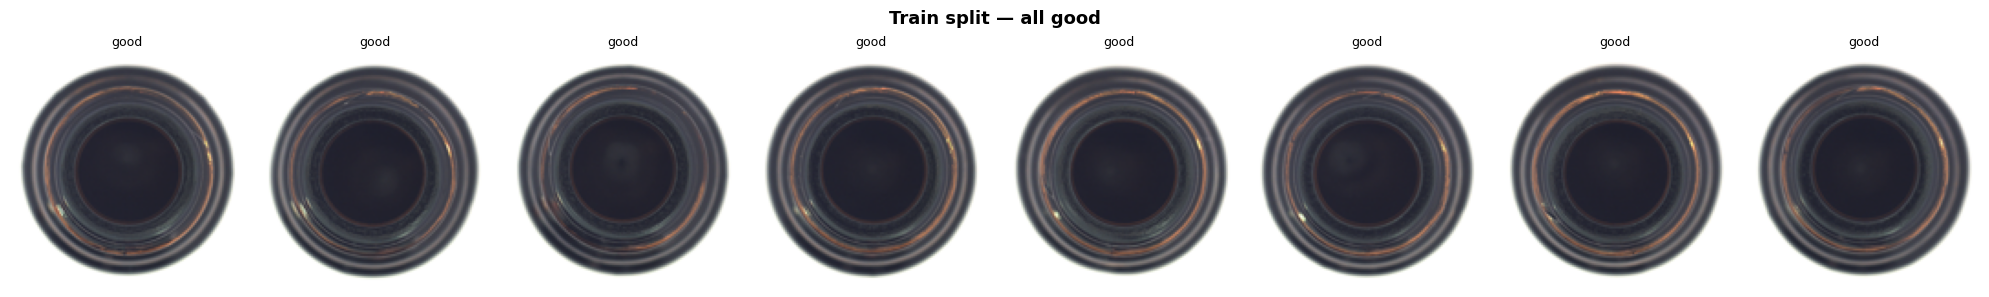

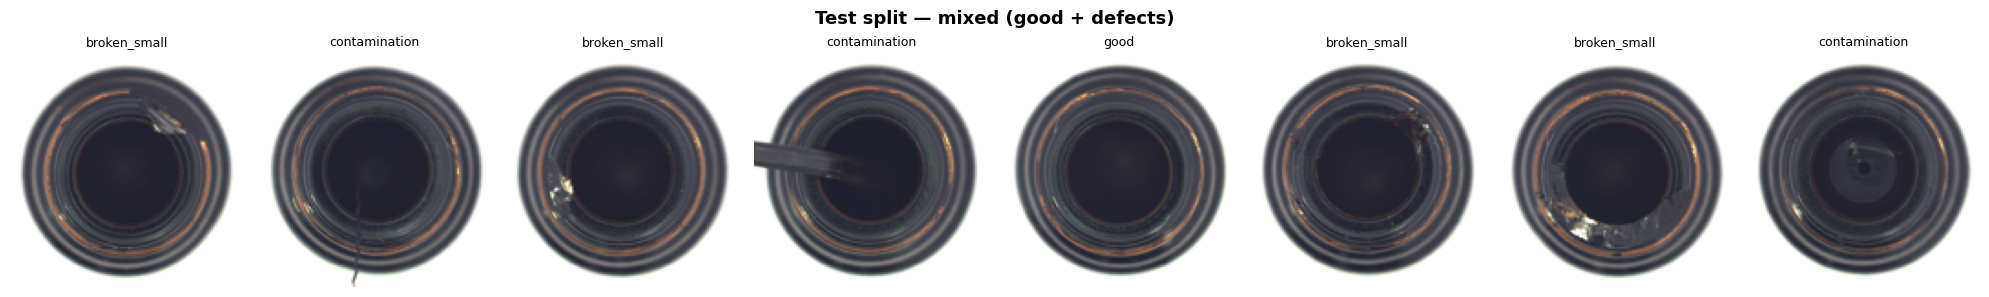

In [6]:
# ── Show sample images from train and test splits ────────────
def show_samples(hf_dataset, title, n=8):
    fig, axes = plt.subplots(1, n, figsize=(2.5 * n, 3))
    indices = random.sample(range(len(hf_dataset)), min(n, len(hf_dataset)))
    for ax, idx in zip(axes, indices):
        row = hf_dataset[idx]
        img = row["image_path"].convert("RGB").resize((128, 128))
        label = row.get("defect", "?")
        ax.imshow(img)
        ax.set_title(label, fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

show_samples(hf_train, "Train split — all good")
show_samples(hf_test,  "Test split — mixed (good + defects)")


## 3. Training — Knowledge Distillation

### Loss function

For each training image $x$ (normal only):

$$\mathcal{L}_{\text{KD}}(x) = \frac{1}{C \cdot H' \cdot W'} \sum_{c,h,w} \left( T(x)_{c,h,w} - S(x)_{c,h,w} \right)^2$$

### Hard example mining

Following EfficientAD, we keep only the **hardest $p$\%** of spatial positions per image to prevent the student from becoming too good too quickly:

$$\mathcal{L}_{\text{hard}}(x) = \text{mean}\!\Big(\text{top-}p\%\big(\| T(x) - S(x) \|^2\big)\Big)$$

The percentile $p$ is annealed: $p_{\text{hard}} = 1 - (1 - p_{\min}) \cdot \frac{\text{epoch}}{\text{total epochs}}$ where $p_{\min} = 0.999$ initially → $0.99$ at the end.

### Normalisation of teacher outputs

Before computing the loss, we **channel-wise normalise** teacher outputs using running mean/std computed over the training set. This stabilises training and makes anomaly scores comparable across channels.

In [7]:
# ── Compute channel-wise mean / std of teacher outputs ───────
@torch.no_grad()
def compute_teacher_stats(teacher, loader, device):
    """Compute channel-wise mean and std of teacher feature maps over a dataset."""
    channels_sum = None
    channels_sq_sum = None
    num_pixels = 0

    for imgs, *_ in loader:
        imgs = imgs.to(device)
        feats = teacher(imgs)  # (B, C, H', W')
        B, C, H, W = feats.shape
        feats_flat = feats.permute(1, 0, 2, 3).reshape(C, -1)  # (C, B*H*W)
        if channels_sum is None:
            channels_sum = feats_flat.sum(dim=1)
            channels_sq_sum = (feats_flat ** 2).sum(dim=1)
        else:
            channels_sum += feats_flat.sum(dim=1)
            channels_sq_sum += (feats_flat ** 2).sum(dim=1)
        num_pixels += B * H * W

    mean = channels_sum / num_pixels           # (C,)
    std = torch.sqrt(channels_sq_sum / num_pixels - mean ** 2)  # (C,)
    return mean, std

teacher_mean, teacher_std = compute_teacher_stats(teacher, train_loader, DEVICE)
print(f"Teacher feature stats — mean range: [{teacher_mean.min():.3f}, {teacher_mean.max():.3f}], "
      f"std range: [{teacher_std.min():.3f}, {teacher_std.max():.3f}]")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Teacher feature stats — mean range: [-0.552, 0.530], std range: [0.105, 0.219]


In [ ]:
# ── Training loop ─────────────────────────────────────────────

def normalise_teacher_features(feats, mean, std):
    """Channel-wise normalise teacher features."""
    return (feats - mean[None, :, None, None]) / (std[None, :, None, None] + 1e-6)


def kd_loss_with_hard_mining(t_feats, s_feats, p_hard):
    """MSE loss with hard-example mining: keep top p_hard fraction of pixels."""
    diff = (t_feats - s_feats) ** 2          # (B, C, H, W)
    pixel_loss = diff.mean(dim=1)            # (B, H, W) — average over channels
    B, H, W = pixel_loss.shape
    flat = pixel_loss.view(B, -1)            # (B, H*W)
    k = max(1, int(flat.shape[1] * p_hard))
    topk_vals, _ = flat.topk(k, dim=1)
    return topk_vals.mean()


optimizer = torch.optim.Adam(student.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=LR * 0.01)

t_mean = teacher_mean.to(DEVICE)
t_std  = teacher_std.to(DEVICE)

loss_history = []
student.train()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_loss = 0.0
    # Anneal hard-mining percentile from 0.999 → 0.99
    p_hard = 1.0 - (1.0 - 0.999) * (1.0 - (epoch - 1) / NUM_EPOCHS)  # starts ~0.999, ends ~0.99

    for imgs, *_ in train_loader:
        imgs = imgs.to(DEVICE)

        with torch.no_grad():
            t_feats = teacher(imgs)
            t_feats = normalise_teacher_features(t_feats, t_mean, t_std)

        s_feats = student(imgs)
        loss = kd_loss_with_hard_mining(t_feats, s_feats, p_hard)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * imgs.size(0)

    scheduler.step()
    avg_loss = epoch_loss / len(train_ds)
    loss_history.append(avg_loss)

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{NUM_EPOCHS} | Loss: {avg_loss:.6f} | p_hard: {p_hard:.4f} | lr: {scheduler.get_last_lr()[0]:.2e}")

print("Training complete.")

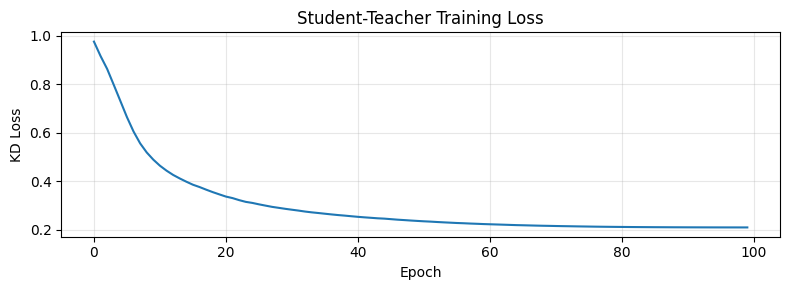

In [ ]:
# ── Training loss curve ───────────────────────────────────────
plt.figure(figsize=(8, 3))
plt.plot(loss_history, linewidth=1.5)
plt.xlabel("Epoch")
plt.ylabel("KD Loss")
plt.title("Student-Teacher Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Inference — Anomaly Map Computation

At test time we compute:

$$\mathcal{A}(x)_{h,w} = \frac{1}{C}\sum_c \left( \hat{T}(x)_{c,h,w} - S(x)_{c,h,w} \right)^2$$

where $\hat{T}$ denotes the channel-normalised teacher features.

**Post-processing:**
1. **Upsample** the anomaly map from $(H', W')$ to the original $(H, W)$ using bilinear interpolation.
2. **Gaussian smoothing** ($\sigma = 4$) to suppress noise and produce cleaner boundaries.
3. **Image-level score** = $\max_{h,w} \mathcal{A}(x)_{h,w}$ (maximum anomaly value).

We also compute the **AUROC** at both image level and pixel level to evaluate detection quality.

In [ ]:
from sklearn.metrics import roc_auc_score

# ── Inference ─────────────────────────────────────────────────
@torch.no_grad()
def predict(teacher, student, loader, t_mean, t_std, device, img_size=IMAGE_SIZE, sigma=4):
    """Run inference — return anomaly maps, labels, masks, image paths."""
    teacher.eval()
    student.eval()

    all_maps = []
    all_labels = []
    all_masks = []
    all_paths = []

    for imgs, masks, labels, defect_types in loader:
        imgs = imgs.to(device)
        t_feats = teacher(imgs)
        t_feats = normalise_teacher_features(t_feats, t_mean, t_std)
        s_feats = student(imgs)

        diff = (t_feats - s_feats) ** 2       # (B, C, H', W')
        amap = diff.mean(dim=1, keepdim=True)  # (B, 1, H', W')
        # Upsample to input resolution
        amap = F.interpolate(amap, size=(img_size, img_size), mode="bilinear", align_corners=False)
        amap = amap.squeeze(1).cpu().numpy()   # (B, H, W)

        for i in range(amap.shape[0]):
            smoothed = gaussian_filter(amap[i], sigma=sigma)
            all_maps.append(smoothed)
            all_labels.append(labels[i].item())
            all_masks.append(masks[i].squeeze(0).numpy())
            all_paths.append(defect_types[i])

    return all_maps, all_labels, all_masks, all_paths


anomaly_maps, labels, gt_masks, img_paths = predict(
    teacher, student, test_loader, t_mean, t_std, DEVICE
)

# ── Image-level AUROC ────────────────────────────────────────
image_scores = [m.max() for m in anomaly_maps]
image_auroc = roc_auc_score(labels, image_scores)
print(f"Image-level AUROC: {image_auroc:.4f}")

# ── Pixel-level AUROC ────────────────────────────────────────
# Only evaluate on images that have ground-truth masks (anomalous images)
all_gt = np.concatenate([m.ravel() for m in gt_masks])
all_pred = np.concatenate([m.ravel() for m in anomaly_maps])
pixel_auroc = roc_auc_score(all_gt.astype(int), all_pred)
print(f"Pixel-level AUROC: {pixel_auroc:.4f}")

Image-level AUROC: 0.9810
Pixel-level AUROC: 0.9651


## 5. Visualization — Anomaly Heatmaps

For each test image, we show:

| Column | Content |
|--------|---------|
| **Input** | Original test image |
| **Ground Truth** | Pixel-level defect mask (white = defect) |
| **Anomaly Map** | Predicted heatmap (brighter = more anomalous) |
| **Overlay** | Anomaly heatmap overlaid on the original image |

We visualise a selection of **anomalous** images to inspect localisation quality, plus a few **good** images to verify low false-positive activation.

In [ ]:
# ── Helper: denormalise image for display ─────────────────────
def denormalize(img_tensor):
    """Convert normalised tensor (C,H,W) back to (H,W,C) numpy in [0,1]."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = img_tensor.cpu() * std + mean
    return img.permute(1, 2, 0).clamp(0, 1).numpy()


def visualize_results(indices, anomaly_maps, gt_masks, dataset, title="Anomaly Detection Results"):
    """Visualise input | GT mask | anomaly map | overlay for given indices."""
    n = len(indices)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes[None, :]

    # Use a shared colormap range across all shown anomaly maps
    vmax = max(anomaly_maps[i].max() for i in indices) * 0.8

    for row, idx in enumerate(indices):
        img_tensor, mask, label, path = dataset[idx]
        img_np = denormalize(img_tensor)
        gt_np = gt_masks[idx]
        amap = anomaly_maps[idx]

        tag = f"[{path}] score={amap.max():.3f}"

        # Input image
        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title(f"Input — {tag}", fontsize=10)
        axes[row, 0].axis("off")

        # Ground truth mask
        axes[row, 1].imshow(gt_np, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground Truth", fontsize=10)
        axes[row, 1].axis("off")

        # Anomaly map
        axes[row, 2].imshow(amap, cmap="hot", vmin=0, vmax=vmax)
        axes[row, 2].set_title("Anomaly Map", fontsize=10)
        axes[row, 2].axis("off")

        # Overlay
        axes[row, 3].imshow(img_np)
        axes[row, 3].imshow(amap, cmap="hot", alpha=0.5, vmin=0, vmax=vmax)
        axes[row, 3].set_title("Overlay", fontsize=10)
        axes[row, 3].axis("off")

    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()


# ── Pick samples: anomalous + good ───────────────────────────
anomalous_indices = [i for i, l in enumerate(labels) if l == 1]
good_indices      = [i for i, l in enumerate(labels) if l == 0]

# Sort anomalous by score descending — show top-6
anomalous_indices_sorted = sorted(anomalous_indices, key=lambda i: anomaly_maps[i].max(), reverse=True)

print("=== Top-6 Anomalous (highest scores) ===")
visualize_results(anomalous_indices_sorted[:6], anomaly_maps, gt_masks, test_ds,
                  title="Top-6 Anomalous Images")

print("\n=== 3 Good Images (should have low activation) ===")
visualize_results(good_indices[:3], anomaly_maps, gt_masks, test_ds,
                  title="Good Images (should be clean)")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ── Failure analysis: hardest cases, shared colour scale ─────────
scores = np.array([m.max() for m in anomaly_maps])
labels_np = np.array(labels)
types = np.array(img_paths)

print("Score summary per class:")
for t in sorted(set(types)):
    s = scores[types == t]
    print(f"  {t:15s} n={len(s):3d}  mean={s.mean():.3f}  min={s.min():.3f}  max={s.max():.3f}")

# Per-defect-type image AUROC (good vs each defect type)
good_s = scores[labels_np == 0]
print("\nImage AUROC per defect type:")
for t in sorted(set(types[labels_np == 1])):
    d = scores[types == t]
    y = np.r_[np.zeros(len(good_s)), np.ones(len(d))]
    print(f"  {t:15s} {roc_auc_score(y, np.r_[good_s, d]):.4f}")

# Hardest cases: lowest-scoring defects + highest-scoring good images
worst_anom = sorted(anomalous_indices, key=lambda i: scores[i])[:3]
worst_good = sorted(good_indices, key=lambda i: scores[i], reverse=True)[:3]
print(f"\nHighest good score: {good_s.max():.3f} | Lowest defect score: {scores[labels_np==1].min():.3f}")
visualize_results(worst_anom + worst_good, anomaly_maps, gt_masks, test_ds,
                  title="Hardest cases: missed defects (top 3) vs. false alarms (bottom 3)")

Output hidden; open in https://colab.research.google.com to view.

In [1]:
import platform
from importlib.metadata import version, PackageNotFoundError

PACKAGES = ["anomalib", "torch", "torchvision", "lightning", "scikit-learn",
            "pandas", "numpy", "matplotlib", "pillow"]
pinned = []
for name in PACKAGES:
    try:
        pinned.append(f"{name}=={version(name)}")
    except PackageNotFoundError:
        pinned.append(f"# {name} not installed")
(OUT / "requirements_pinned.txt").write_text("\n".join(pinned) + "\n")
print("\n".join(pinned))      # copy these into requirements.txt in your repo

info = dict(python=platform.python_version(), torch=torch.__version__, anomalib=getattr(anomalib, "__version__", "unknown"),
            gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
            max_steps=MAX_STEPS, seed=SEED, categories=CATEGORIES)
(OUT / "environment.json").write_text(json.dumps(info, indent=2))
print(json.dumps(info, indent=2))

NameError: name 'OUT' is not defined